# Component 2: Vehicle Damage Image Classification with a CNN

This notebook develops a convolutional neural network that classifies photographs of vehicle damage into six types: crack, dent, glass shatter, lamp broken, scratch and tire flat. The intended application is insurance claim verification, where the damage type has to be identified from an image consistently. The sections follow the structure of the report, and the figures saved here are the ones the report uses.

In [1]:
# All imports collected here so the dependencies are visible in one place
import os
import shutil
import warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # Suppress TensorFlow startup logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from tensorflow.keras.utils import image_dataset_from_directory, to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, BatchNormalization, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

sns.set_style('whitegrid')

## Configuration

`DATA_DIR` is the only path that has to be set. Where the images are already arranged in one sub-folder per damage type, no further configuration is needed. Where they sit in a single flat folder alongside a CSV of labels, which is the layout of the Ripik dataset, `CSV_PATH` and `IMAGE_FOLDER` must also be set and the column names checked against the CSV. The following section then sorts the images into class folders.

The training settings are collected in this cell so that every experiment below draws its parameters from one place.

In [2]:
# ---- Paths. The archive folder sits alongside this notebook ----
DATA_DIR     = "archive"
CSV_PATH     = "archive/train/train/train.csv"
IMAGE_FOLDER = "archive/train/train/images"

# ---- Identify the CSV column names automatically ----
_df = pd.read_csv(CSV_PATH)
print("CSV columns:", list(_df.columns))

def _looks_like_image_name(series, image_folder):
    # Count how many values in this column resolve to an actual image file
    hits = 0
    for v in series.head(50).astype(str):
        if os.path.exists(os.path.join(image_folder, v)):
            hits += 1
        else:
            for ext in ('.jpg', '.jpeg', '.png'):
                if os.path.exists(os.path.join(image_folder, v + ext)):
                    hits += 1
                    break
    return hits

# The filename column is the one whose values match image files on disk
_scores = {c: _looks_like_image_name(_df[c], IMAGE_FOLDER) for c in _df.columns}
NAME_COL = max(_scores, key=_scores.get)

# The label column is the remaining column with the fewest unique values, being the six classes
_others = [c for c in _df.columns if c != NAME_COL]
LABEL_COL = min(_others, key=lambda c: _df[c].nunique())

print("Using NAME_COL =", NAME_COL, "| LABEL_COL =", LABEL_COL)
print("Classes found in csv:", sorted(_df[LABEL_COL].astype(str).str.strip().unique()))

# ---- Training settings ----
IMG_SIZE = (128, 128)
SEED = 42
EPOCHS = 30                 # Main model. Early stopping normally halts training before this limit
EXP_EPOCHS = 15             # Shorter runs for the hyperparameter experiments
BATCH_SIZE = 32
RUN_EXPERIMENTS = True      # Set to False to train the main model only
OUTPUT_DIR = "outputs"

np.random.seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

def outpath(name):
    return os.path.join(OUTPUT_DIR, name)

CSV columns: ['image_id', 'filename', 'label']
Using NAME_COL = image_id | LABEL_COL = label
Classes found in csv: ['1', '2', '3', '4', '5', '6']


In [3]:
# The CSV labels the classes as the numbers 1 to 6.
# Mapping them to damage names keeps the folders, figures and report readable.
ORIGINAL_CSV = "archive/train/train/train.csv"
NAMED_CSV    = "archive/train/train/train_named.csv"

label_names = {
    "1": "crack",
    "2": "scratch",
    "3": "tire_flat",
    "4": "dent",
    "5": "glass_shatter",
    "6": "lamp_broken",
}

# Always read the original CSV so that re-running this cell is safe
_df = pd.read_csv(ORIGINAL_CSV)
_df[LABEL_COL] = _df[LABEL_COL].astype(str).str.strip().map(label_names)

# Stop here if any label failed to map rather than carrying NaN labels forward
if _df[LABEL_COL].isna().any():
    raise ValueError("some labels did not map, check label_names against the csv")

_df.to_csv(NAMED_CSV, index=False)
CSV_PATH = NAMED_CSV
print(_df[LABEL_COL].value_counts())

label
scratch          2349
dent             2079
glass_shatter    1185
lamp_broken       882
tire_flat         534
crack             171
Name: count, dtype: int64


## Data layout

These functions locate the class folders. Where the dataset is a flat folder with a CSV, they build one sub-folder per class and copy the images into it. Resolving the layout in code rather than by hand allows the notebook to run from top to bottom on either arrangement.

In [4]:
def count_class_subfolders(folder):
    # Count the sub-folders that contain images.
    # A class layout has several, one per damage type.
    if not os.path.isdir(folder):
        return 0
    n = 0
    for d in os.listdir(folder):
        sub = os.path.join(folder, d)
        if os.path.isdir(sub):
            imgs = [f for f in os.listdir(sub) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            if len(imgs) > 0:
                n += 1
    return n

def sort_from_csv(image_folder, csv_path, out_dir):
    # Build one sub-folder per class by copying the images listed in the CSV
    df = pd.read_csv(csv_path)
    copied = missing = 0
    for _, row in df.iterrows():
        name = str(row[NAME_COL])
        label = str(row[LABEL_COL]).strip()
        src = os.path.join(image_folder, name)
        if not os.path.exists(src):                      # Add the file extension where the CSV omits it
            for ext in ('.jpg', '.jpeg', '.png'):
                if os.path.exists(os.path.join(image_folder, name + ext)):
                    src = os.path.join(image_folder, name + ext)
                    break
        if not os.path.exists(src):
            missing += 1
            continue
        class_dir = os.path.join(out_dir, label)
        os.makedirs(class_dir, exist_ok=True)
        shutil.copy2(src, os.path.join(class_dir, os.path.basename(src)))
        copied += 1
    print(f'Sorted {copied} images into class folders ({missing} listed in csv but not found).')

def resolve_data_dir():
    # At least two class folders are needed so a single 'images' folder is not mistaken for a class
    if count_class_subfolders(DATA_DIR) >= 2:
        return DATA_DIR
    train_sub = os.path.join(DATA_DIR, "train")   # The classes sometimes sit inside a 'train' folder
    if count_class_subfolders(train_sub) >= 2:
        return train_sub
    if CSV_PATH and os.path.exists(CSV_PATH):      # Otherwise sort a flat folder using the CSV
        img_folder = IMAGE_FOLDER if IMAGE_FOLDER else DATA_DIR
        sorted_dir = DATA_DIR.rstrip('/\\') + "_sorted"
        if count_class_subfolders(sorted_dir) < 2:
            sort_from_csv(img_folder, CSV_PATH, sorted_dir)
        return sorted_dir
    raise SystemExit("Could not find class folders in DATA_DIR. If your images are in one flat "
                     "folder with a csv, set CSV_PATH and IMAGE_FOLDER in the config cell.")

## Loading the images

`image_dataset_from_directory` reads the images from the class sub-folders and takes the class names from the folder names. The images are converted to NumPy arrays so that the remaining steps work on standard arrays rather than on a TensorFlow dataset object.

In [5]:
from PIL import Image

# A previous run emptied the sorted folder, so it is deleted and rebuilt from the CSV.
# The original images folder is only ever copied from, so it remains untouched.
for folder in ["archive_sorted", "archive_sorted_unreadable"]:
    if os.path.isdir(folder):
        shutil.rmtree(folder)
        print("removed", folder)

data_dir = resolve_data_dir()      # Re-sorts the images into class folders
print("Using:", data_dir)

# Check which images open successfully. Only image errors are caught here, so that a
# missing import cannot be mistaken for a corrupt file.
bad_dir = data_dir.rstrip('/\\') + "_unreadable"
checked = 0
bad_files = []
for class_name in sorted(os.listdir(data_dir)):
    class_path = os.path.join(data_dir, class_name)
    if not os.path.isdir(class_path):
        continue
    for fname in sorted(os.listdir(class_path)):
        fpath = os.path.join(class_path, fname)
        checked += 1
        try:
            with Image.open(fpath) as im:     # Checks the file header
                im.verify()
            with Image.open(fpath) as im:     # Checks that the pixel data decodes
                im.convert('RGB').load()
        except (OSError, ValueError, SyntaxError):
            bad_files.append((class_name, fname))

print(f'Checked {checked} images, {len(bad_files)} unreadable.')

# If nearly every file appears unreadable the cause is something other than corrupt images
if len(bad_files) > checked * 0.5:
    raise RuntimeError('More than half the images failed to open. Stopping instead of moving them.')

for class_name, fname in bad_files:
    os.makedirs(os.path.join(bad_dir, class_name), exist_ok=True)
    shutil.move(os.path.join(data_dir, class_name, fname),
                os.path.join(bad_dir, class_name, fname))
print(f'Moved {len(bad_files)} unreadable images out of the dataset.')

removed archive_sorted
Sorted 7200 images into class folders (0 listed in csv but not found).
Using: archive_sorted
Checked 7200 images, 0 unreadable.
Moved 0 unreadable images out of the dataset.


In [6]:
# Load the images into NumPy arrays. The class names come from the folder names.
ds = image_dataset_from_directory(
    data_dir, label_mode='int', image_size=IMG_SIZE,
    batch_size=None, shuffle=False)

class_names = ds.class_names
n_classes = len(class_names)

xs, ys = [], []
for img, lab in ds:
    xs.append(img.numpy().astype('uint8'))
    ys.append(int(lab.numpy()))
x = np.stack(xs)
y = np.array(ys)

print('Loaded', x.shape, '| classes:', class_names)

Found 7200 files belonging to 6 classes.
Loaded (7200, 128, 128, 3) | classes: ['crack', 'dent', 'glass_shatter', 'lamp_broken', 'scratch', 'tire_flat']


## Examining the data

The distribution of images across classes determines how the later results have to be read. Where one class is much larger than the others, a model can reach a high overall accuracy by predicting that class for most inputs while performing poorly on the rare ones. The rare damage types matter as much as the common ones for claim verification, so the class counts and one example image per class are inspected before any modelling.

Images per class:
  crack          : 171
  dent           : 2079
  glass_shatter  : 1185
  lamp_broken    : 882
  scratch        : 2349
  tire_flat      : 534


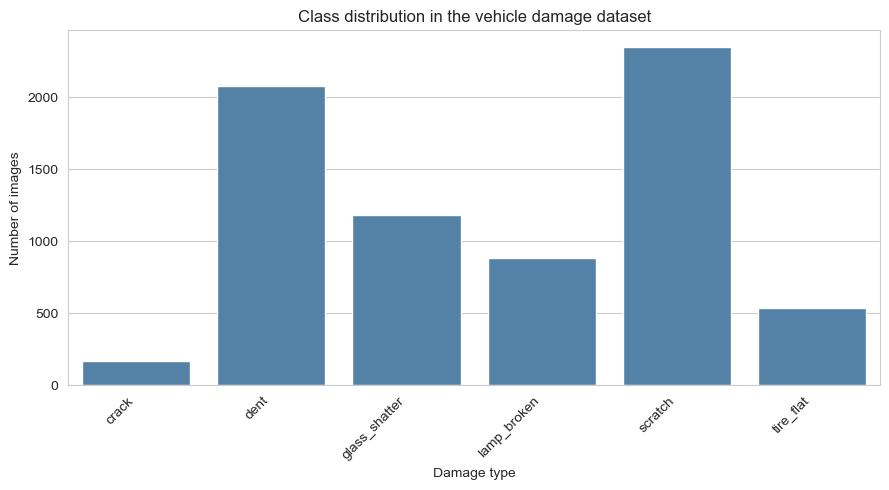

In [7]:
# Count the images in each class
counts_all = Counter(y)
print('Images per class:')
for i, name in enumerate(class_names):
    print(f'  {name:15s}: {counts_all[i]}')

plt.figure(figsize=(9, 5))
sns.barplot(x=list(class_names), y=[counts_all[i] for i in range(n_classes)], color='steelblue')
plt.xlabel('Damage type'); plt.ylabel('Number of images')
plt.title('Class distribution in the vehicle damage dataset')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(outpath('fig_class_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()

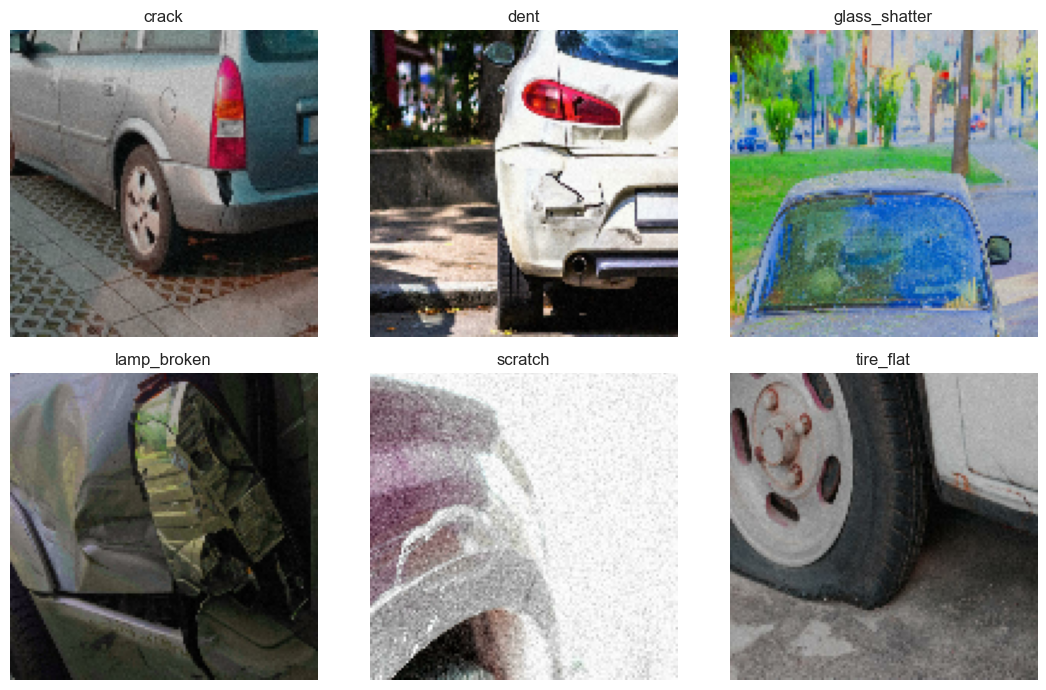

In [8]:
# One example image from each class
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
axes = axes.flatten()
for i, name in enumerate(class_names):
    idx = np.where(y == i)[0][0]
    axes[i].imshow(x[idx]); axes[i].set_title(name); axes[i].axis('off')
plt.tight_layout()
plt.savefig(outpath('fig_sample_images.png'), dpi=300, bbox_inches='tight')
plt.show()

## Preprocessing

Three operations are applied here. Pixel values are scaled to the range 0 to 1, which keeps the gradients stable during training. Labels are one hot encoded to match the softmax output. The data is then split into training, validation and test sets using stratified sampling, so that each class keeps its proportion in every split. The test set is not used again until the final evaluation.

In [9]:
x = x.astype('float32') / 255.0
y_cat = to_categorical(y)

x_train, x_test, y_train_cat, y_test_cat, y_train_int, y_test_int = train_test_split(
    x, y_cat, y, test_size=0.2, random_state=SEED, stratify=y)
x_train, x_val, y_train_cat, y_val_cat, y_train_int, y_val_int = train_test_split(
    x_train, y_train_cat, y_train_int, test_size=0.2, random_state=SEED, stratify=y_train_int)

print(f'Training:   {len(x_train)}')
print(f'Validation: {len(x_val)}')
print(f'Test:       {len(x_test)}')

Training:   4608
Validation: 1152
Test:       1440


## Class imbalance

The class counts are uneven, so each class is given a weight during training. The weight is the total number of training samples divided by the product of the number of classes and that class count, which makes it inversely proportional to class frequency. Passing these weights to `fit` increases the loss incurred by misclassifying a rare class and leaves the data itself unchanged.

Class weighting is declared as an exception in the report, and is used here because the imbalance is severe enough to collapse an unweighted model onto the two largest classes.

In [10]:
counts_train = Counter(y_train_int)
total_train = len(y_train_int)
class_weights = {cls: total_train / (n_classes * cnt) for cls, cnt in counts_train.items()}

print('Class weights (higher = rarer class):')
for cls in sorted(class_weights):
    print(f'  {class_names[cls]:15s}: {class_weights[cls]:.3f}')

Class weights (higher = rarer class):
  crack          : 6.982
  dent           : 0.577
  glass_shatter  : 1.013
  lamp_broken    : 1.359
  scratch        : 0.511
  tire_flat      : 2.246


## Data augmentation

The dataset holds a few thousand images, which is modest for training a network from scratch. Augmentation generates modified copies of the training images as training proceeds, using random rotation, shifts, shear, zoom and horizontal flips. This increases the variety the model sees and makes memorising individual photographs harder.

The transformations suit photographs of vehicles. Horizontal flipping is appropriate because damage on the left and right of a vehicle is equivalent. Vertical flipping is excluded because vehicles are not photographed upside down. Augmentation is applied to the training set only, so that validation and test performance are measured on unmodified images.

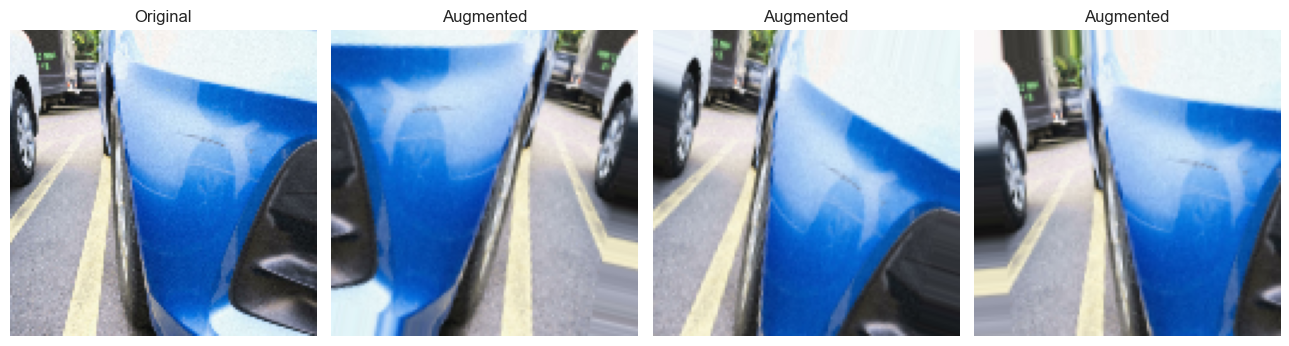

In [11]:
train_datagen = ImageDataGenerator(
    rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, shear_range=0.1, horizontal_flip=True,
    vertical_flip=False, fill_mode='nearest')
train_datagen.fit(x_train)

# Display an original image alongside several augmented versions
example = x_train[0]
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
axes[0].imshow(example); axes[0].set_title('Original'); axes[0].axis('off')
for i in range(1, 4):
    axes[i].imshow(train_datagen.random_transform(example)); axes[i].set_title('Augmented'); axes[i].axis('off')
plt.tight_layout()
plt.savefig(outpath('fig_augmentation.png'), dpi=300, bbox_inches='tight')
plt.show()

## CNN architecture (report part a)

The architecture is defined as a function so that every experiment below trains an identical network and only the parameter under investigation changes.

The network has three convolutional blocks followed by a dense classification head. Each block applies a convolutional layer with 3x3 kernels and ReLU activation, a 2x2 max pooling layer, and batch normalisation. The blocks use 32, 64 and 128 filters, increasing with depth so that the early layers can represent edges and textures while the later layers combine these into patterns specific to each damage type. ReLU is preferred to sigmoid activation because it trains faster and does not saturate, which avoids the vanishing gradient problem. Max pooling halves the spatial dimensions after each block and keeps the strongest activation in each region. Batch normalisation standardises the activations passed between blocks, which stabilises training.

The head flattens the final feature maps into a dense layer of 64 neurons with ReLU activation, applies dropout, and ends in a six neuron softmax layer giving one probability per class. The model is compiled with the Adam optimiser at a learning rate of 0.0001, the value selected by the tuning section below, and categorical cross entropy loss, which is the standard loss for multi class classification with one hot labels.

In [12]:
def build_cnn(input_shape, n_classes, dropout_rate=0.5, use_batchnorm=True,
              learning_rate=0.001, kernel_size=(3, 3), pooling='max'):
    # Three convolutional blocks with 32, 64 and 128 filters, followed by a dense head
    model = Sequential()

    model.add(Conv2D(32, kernel_size, activation='relu', padding='same', input_shape=input_shape))
    model.add(MaxPooling2D((2, 2)) if pooling == 'max' else AveragePooling2D((2, 2)))
    if use_batchnorm:
        model.add(BatchNormalization())

    model.add(Conv2D(64, kernel_size, activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)) if pooling == 'max' else AveragePooling2D((2, 2)))
    if use_batchnorm:
        model.add(BatchNormalization())

    model.add(Conv2D(128, kernel_size, activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)) if pooling == 'max' else AveragePooling2D((2, 2)))
    if use_batchnorm:
        model.add(BatchNormalization())

    model.add(Flatten())
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(Dense(n_classes, activation='softmax'))

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def make_early_stopping(patience=10):
    return EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)
model = build_cnn(input_shape, n_classes, dropout_rate=0.25, learning_rate=0.0001)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,097,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,191,750 (8.36 MB)

 Trainable params: 2,191,302 (8.36 MB)

 Non-trainable params: 448 (1.75 KB)

## Training the main model

The model is trained on the augmented images and validated on the unmodified validation set, with the class weights applied. Early stopping monitors the validation loss and restores the weights from the best epoch, so that the final model is not taken from an epoch at which it had started to overfit.

In [13]:
history = model.fit(
    train_datagen.flow(x_train, y_train_cat, batch_size=BATCH_SIZE),
    validation_data=(x_val, y_val_cat), epochs=EPOCHS,
    class_weight=class_weights, callbacks=[make_early_stopping()], verbose=1)

Epoch 1/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 29s 188ms/step - accuracy: 0.3032 - loss: 1.7260 - val_accuracy: 0.0269 - val_loss: 2.7998
Epoch 2/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 28s 192ms/step - accuracy: 0.3800 - loss: 1.3783 - val_accuracy: 0.2760 - val_loss: 2.7291
Epoch 3/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.4156 - loss: 1.3068 - val_accuracy: 0.3750 - val_loss: 2.1995
Epoch 4/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 29s 202ms/step - accuracy: 0.4273 - loss: 1.2510 - val_accuracy: 0.4280 - val_loss: 1.5728
Epoch 5/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 29s 202ms/step - accuracy: 0.4562 - loss: 1.1850 - val_accuracy: 0.4314 - val_loss: 1.5200
Epoch 6/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 31s 216ms/step - accuracy: 0.4538 - loss: 1.1587 - val_accuracy: 0.4922 - val_loss: 1.2974
Epoch 7/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 32s 225ms/step - accuracy: 0.4779 - loss: 1.1104 - val_accuracy: 0.4549 - val_loss: 1.4220
Epoch 8/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 32s 221ms/step - accuracy: 0.4766 - loss: 1

## Training curves (report part d)

These curves are the evidence for the overfitting discussion in the report. Training accuracy rising well above validation accuracy, or validation loss increasing while training loss continues to fall, indicates that the model is fitting the training set rather than learning features that generalise. Curves that track each other indicate the opposite.

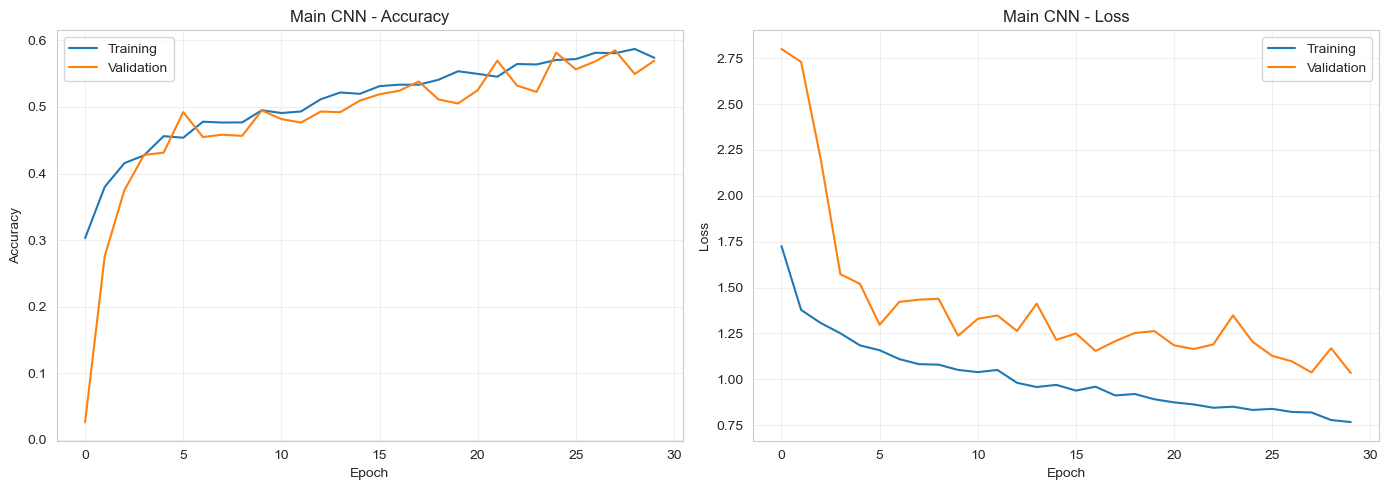

Final training accuracy:   0.5738
Final validation accuracy: 0.5694
Gap (train - val):         0.0043


In [14]:
def plot_history(history, title, fname):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(h['accuracy'], label='Training'); axes[0].plot(h['val_accuracy'], label='Validation')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].set_title(f'{title} - Accuracy'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(h['loss'], label='Training'); axes[1].plot(h['val_loss'], label='Validation')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].set_title(f'{title} - Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.savefig(fname, dpi=300, bbox_inches='tight'); plt.show()

plot_history(history, 'Main CNN', outpath('fig_training_history.png'))

final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
print(f'Final training accuracy:   {final_train_acc:.4f}')
print(f'Final validation accuracy: {final_val_acc:.4f}')
print(f'Gap (train - val):         {final_train_acc - final_val_acc:.4f}')

## Evaluation on the held-out test set

The confusion matrix shows which damage types are mistaken for one another, and the classification report gives precision, recall and F1 for each class. The per class figures are more informative than overall accuracy here, because the imbalance means the overall figure is dominated by the two largest classes.

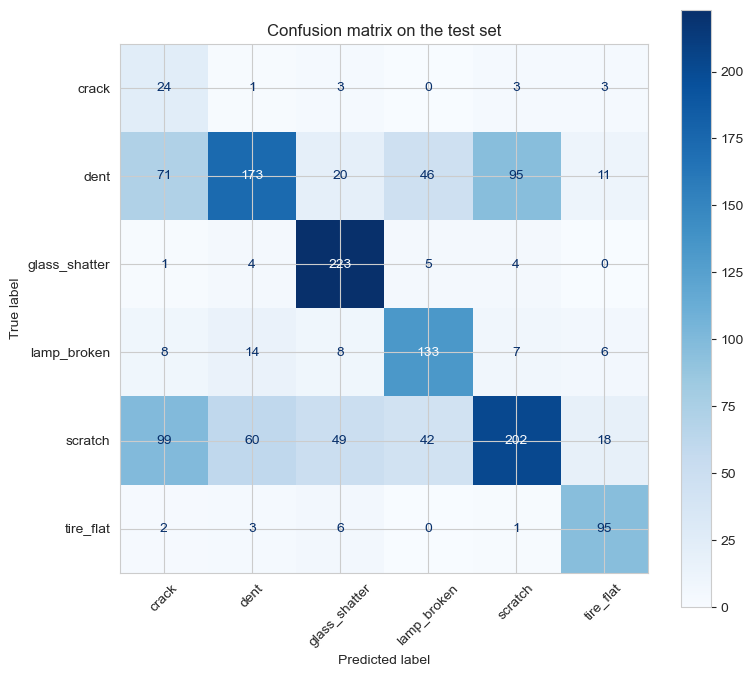

               precision    recall  f1-score   support

        crack       0.12      0.71      0.20        34
         dent       0.68      0.42      0.52       416
glass_shatter       0.72      0.94      0.82       237
  lamp_broken       0.59      0.76      0.66       176
      scratch       0.65      0.43      0.52       470
    tire_flat       0.71      0.89      0.79       107

     accuracy                           0.59      1440
    macro avg       0.58      0.69      0.58      1440
 weighted avg       0.65      0.59      0.60      1440



In [15]:
def evaluate_model(model, x_test, y_test_int, class_names, fname):
    probs = model.predict(x_test, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    cm = confusion_matrix(y_test_int, y_pred, labels=range(len(class_names)))
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45)
    plt.title('Confusion matrix on the test set')
    plt.tight_layout(); plt.savefig(fname, dpi=300, bbox_inches='tight'); plt.show()
    print(classification_report(y_test_int, y_pred, target_names=class_names, zero_division=0))

evaluate_model(model, x_test, y_test_int, class_names, outpath('fig_confusion_matrix.png'))

## Hyperparameter tuning (report part c)

Each experiment trains a new model with one hyperparameter changed and records the best validation accuracy it reaches. The runs use fewer epochs than the final model to keep the total runtime manageable, which is enough to compare the settings against each other rather than to produce a final result. Setting `RUN_EXPERIMENTS = False` in the configuration cell skips this section.

In [16]:
def run_experiment(learning_rate=0.0001, batch_size=32, dropout_rate=0.5, epochs=EXP_EPOCHS):
    m = build_cnn(input_shape, n_classes, dropout_rate=dropout_rate, learning_rate=learning_rate)
    hist = m.fit(train_datagen.flow(x_train, y_train_cat, batch_size=batch_size),
                 validation_data=(x_val, y_val_cat), epochs=epochs,
                 class_weight=class_weights, callbacks=[make_early_stopping()], verbose=0)
    return max(hist.history['val_accuracy'])

In [17]:
lr_results, batch_results, dropout_results = {}, {}, {}

if RUN_EXPERIMENTS:
    print('Learning rate:')
    for lr in [0.01, 0.001, 0.0001]:
        lr_results[lr] = run_experiment(learning_rate=lr)
        print(f'  {lr}: best val accuracy {lr_results[lr]:.4f}')

    print('\nBatch size:')
    for bs in [32, 128]:
        batch_results[bs] = run_experiment(batch_size=bs)
        print(f'  {bs}: best val accuracy {batch_results[bs]:.4f}')

    print('\nDropout rate:')
    for dr in [0.25, 0.5, 0.75]:
        dropout_results[dr] = run_experiment(dropout_rate=dr)
        print(f'  {dr}: best val accuracy {dropout_results[dr]:.4f}')

Learning rate:
  0.01: best val accuracy 0.3247
  0.001: best val accuracy 0.3264
  0.0001: best val accuracy 0.4748

Batch size:
  32: best val accuracy 0.4809
  128: best val accuracy 0.3837

Dropout rate:
  0.25: best val accuracy 0.5234
  0.5: best val accuracy 0.4878
  0.75: best val accuracy 0.3924


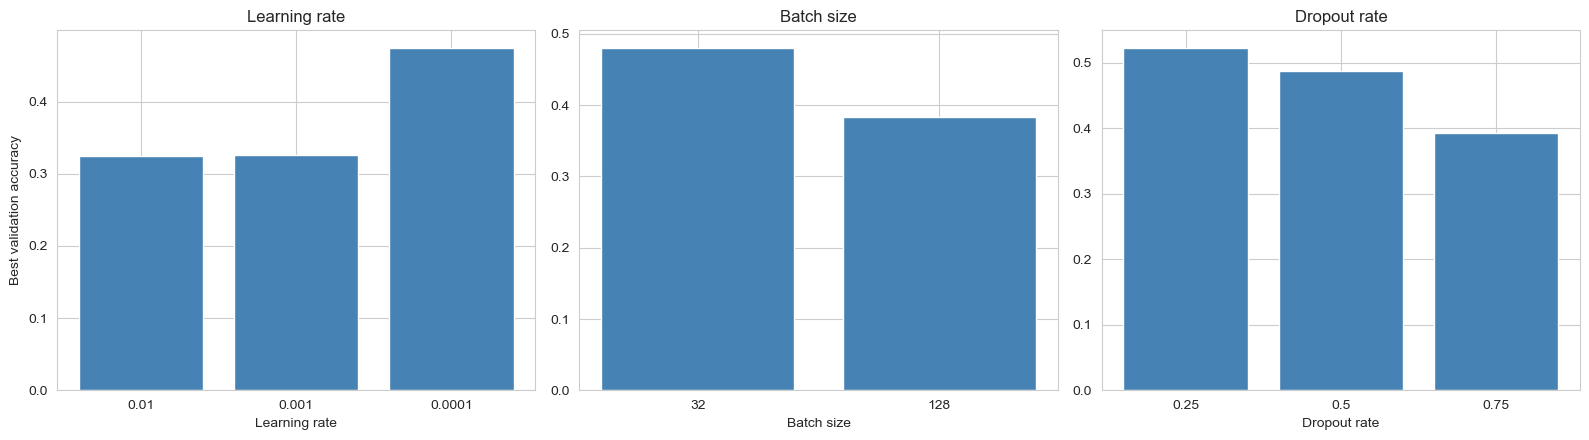

In [18]:
if RUN_EXPERIMENTS:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].bar([str(k) for k in lr_results], list(lr_results.values()), color='steelblue')
    axes[0].set_xlabel('Learning rate'); axes[0].set_ylabel('Best validation accuracy'); axes[0].set_title('Learning rate')
    axes[1].bar([str(k) for k in batch_results], list(batch_results.values()), color='steelblue')
    axes[1].set_xlabel('Batch size'); axes[1].set_title('Batch size')
    axes[2].bar([str(k) for k in dropout_results], list(dropout_results.values()), color='steelblue')
    axes[2].set_xlabel('Dropout rate'); axes[2].set_title('Dropout rate')
    plt.tight_layout(); plt.savefig(outpath('fig_hyperparameter_comparison.png'), dpi=300, bbox_inches='tight'); plt.show()

## Regularisation comparison (report part b)

Two models are trained that differ only in their regularisation. The first has augmentation, dropout and batch normalisation removed, and the second has all three applied. Comparing the gap between training and validation accuracy for each quantifies what the regularisation achieves, rather than simply stating that it was used.

Training a model with NO regularisation...
Training a model WITH regularisation...

No regularisation   -> train 0.9631, val 0.7465, gap 0.2166
With regularisation -> train 0.5749, val 0.5582, gap 0.0167


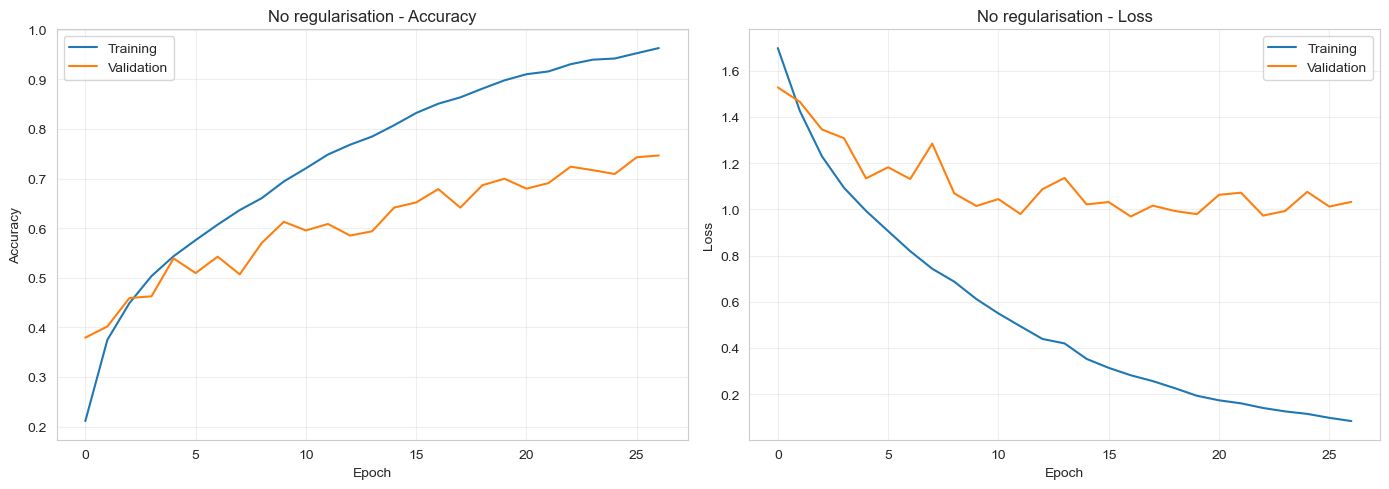

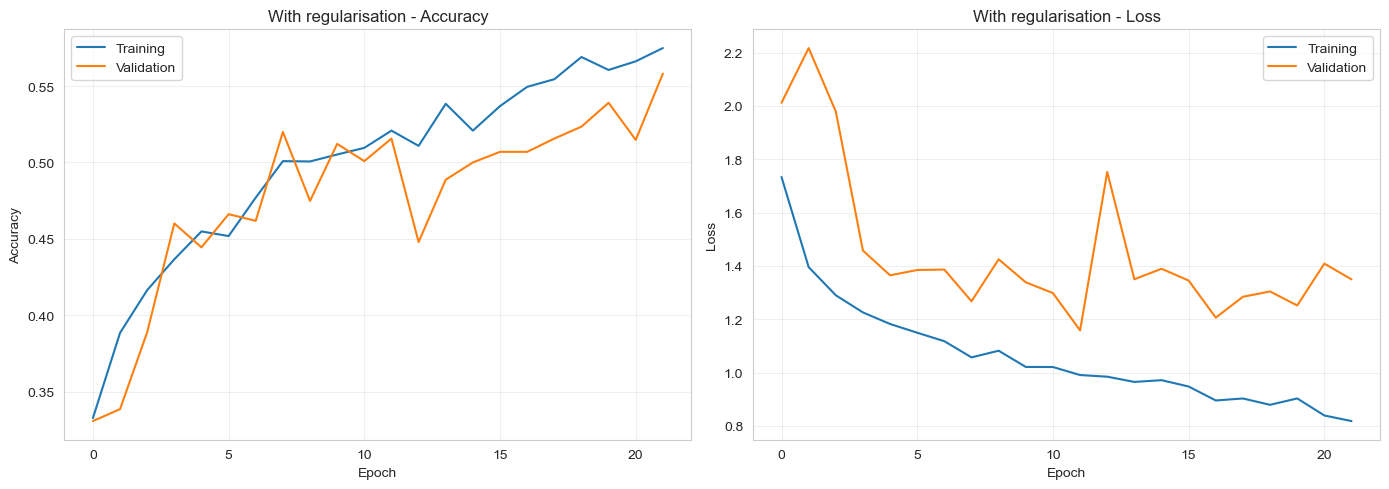

In [19]:
if RUN_EXPERIMENTS:
    print('Training a model with NO regularisation...')
    model_plain = build_cnn(input_shape, n_classes, dropout_rate=0.0, use_batchnorm=False, learning_rate=0.0001)
    hist_plain = model_plain.fit(
        ImageDataGenerator().flow(x_train, y_train_cat, batch_size=BATCH_SIZE),
        validation_data=(x_val, y_val_cat), epochs=EPOCHS,
        class_weight=class_weights, callbacks=[make_early_stopping()], verbose=0)

    print('Training a model WITH regularisation...')
    model_reg = build_cnn(input_shape, n_classes, dropout_rate=0.25, use_batchnorm=True, learning_rate=0.0001)
    hist_reg = model_reg.fit(
        train_datagen.flow(x_train, y_train_cat, batch_size=BATCH_SIZE),
        validation_data=(x_val, y_val_cat), epochs=EPOCHS,
        class_weight=class_weights, callbacks=[make_early_stopping()], verbose=0)

    def gap(h):
        return h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    print(f'\nNo regularisation   -> train {hist_plain.history["accuracy"][-1]:.4f}, '
          f'val {hist_plain.history["val_accuracy"][-1]:.4f}, gap {gap(hist_plain):.4f}')
    print(f'With regularisation -> train {hist_reg.history["accuracy"][-1]:.4f}, '
          f'val {hist_reg.history["val_accuracy"][-1]:.4f}, gap {gap(hist_reg):.4f}')

    plot_history(hist_plain, 'No regularisation', outpath('fig_no_regularisation.png'))
    plot_history(hist_reg, 'With regularisation', outpath('fig_with_regularisation.png'))

## Summary

The notebook loads and sorts the images, trains a three block CNN on augmented and class weighted data, tunes three hyperparameters, and evaluates the resulting model on a held out test set. The figures written to the `outputs` folder map onto the report as follows. The class distribution and example images describe the dataset, the augmentation figure illustrates the transformations, the training curves provide the overfitting evidence, the confusion matrix and classification report give per class performance, the hyperparameter figure compares the tuned settings, and the regularisation pair quantifies the effect of the regularisation.